# Real Madrid AI Transfer Intelligence
## Notebook 03 — Exploratory Data Analysis (EDA)

**Objective:** explore the cleaned Real Madrid player-season dataset for La Liga 2023/24–2025/26. Identify patterns in squad usage, age profile, attacking output and positional coverage that can guide the later transfer-needs analysis.

**Input:** `data/processed/real_madrid_player_season_clean.csv` from Notebook 02.

**Analysis rules**
- Every row represents a player-season record, not an independent player.
- Per-90 statistics must be interpreted together with minutes played.
- Missing values remain missing; charts exclude missing values rather than converting them to zero.
- This notebook describes patterns. It does not claim that a metric caused team success or that a position is definitively weak.


## 1. Load cleaned data and inspect schema

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "processed"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = PROJECT_ROOT / "figures"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

INPUT_PATH = DATA_DIR / "real_madrid_player_season_clean.csv"
if not INPUT_PATH.exists():
    raise FileNotFoundError(
        f"Missing {INPUT_PATH}. Run Notebook 02 and confirm its export path."
    )

df = pd.read_csv(INPUT_PATH)
print("Dataset shape:", df.shape)
print("Unique players:", df["player_id"].nunique() if "player_id" in df else "player_id unavailable")
print("Seasons:", sorted(df["season"].dropna().astype(str).unique()) if "season" in df else "season unavailable")
display(df.head())
display(pd.DataFrame({"column": df.columns, "dtype": df.dtypes.astype(str).values}))


,column,dtype
0,league,str
1,season,int64
2,team,str
3,player_name,str
4,nation,str
...,...,...
78,starts,int64
79,goals,int64
80,player_id,str
81,club,str


## 2. Prepare analysis fields

In [2]:
# Flexible column mapping to support small FBref/SoccerData naming differences.
def first_existing(options):
    return next((col for col in options if col in df.columns), None)

FIELD = {
    "player": first_existing(["player_name", "player"]),
    "season": first_existing(["season"]),
    "minutes": first_existing(["minutes", "min", "playing_time_min"]),
    "matches": first_existing(["matches", "mp", "appearances"]),
    "starts": first_existing(["starts", "playing_time_starts"]),
    "age": first_existing(["age"]),
    "position": first_existing(["position", "pos"]),
    "goals": first_existing(["goals", "gls", "standard_gls"]),
    "assists": first_existing(["assists", "ast", "standard_ast"]),
    "goal_contributions": first_existing(["goal_contributions"]),
    "goals_per_90": first_existing(["goals_per_90"]),
    "assists_per_90": first_existing(["assists_per_90"]),
    "goal_contributions_per_90": first_existing(["goal_contributions_per_90"]),
}
display(pd.DataFrame([{"analysis_field": k, "dataset_column": v} for k, v in FIELD.items()]))

required = ["player", "season"]
missing = [name for name in required if FIELD[name] is None]
if missing:
    raise ValueError(f"Required EDA fields are missing: {missing}. Available columns: {df.columns.tolist()}")

# Create analysis aliases without overwriting source columns.
for alias, source in FIELD.items():
    if source is not None and alias not in df.columns:
        df[alias] = df[source]

for col in ["minutes", "matches", "starts", "age", "goals", "assists",
            "goal_contributions", "goals_per_90", "assists_per_90",
            "goal_contributions_per_90"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

if "goal_contributions" not in df.columns and {"goals", "assists"}.issubset(df.columns):
    df["goal_contributions"] = df["goals"] + df["assists"]

if "minutes" in df.columns:
    if "goals_per_90" not in df.columns and "goals" in df.columns:
        df["goals_per_90"] = np.where(df["minutes"] > 0, df["goals"] * 90 / df["minutes"], np.nan)
    if "assists_per_90" not in df.columns and "assists" in df.columns:
        df["assists_per_90"] = np.where(df["minutes"] > 0, df["assists"] * 90 / df["minutes"], np.nan)
    if "goal_contributions_per_90" not in df.columns and "goal_contributions" in df.columns:
        df["goal_contributions_per_90"] = np.where(
            df["minutes"] > 0, df["goal_contributions"] * 90 / df["minutes"], np.nan
        )

print("Analysis rows:", len(df))


Analysis rows: 92


## 3. Squad participation by season

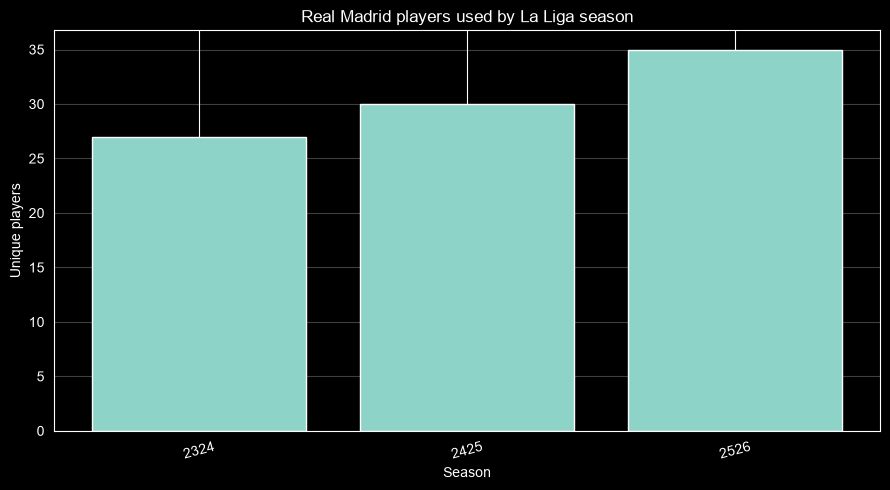

In [3]:
season_summary = (
    df.groupby("season", dropna=False)
      .agg(
          player_season_rows=("player", "size"),
          unique_players=("player", "nunique"),
          total_minutes=("minutes", "sum") if "minutes" in df.columns else ("player", "size"),
          median_minutes=("minutes", "median") if "minutes" in df.columns else ("player", "size"),
          median_age=("age", "median") if "age" in df.columns else ("player", "size"),
      )
      .reset_index()
)
display(season_summary)

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(season_summary["season"].astype(str), season_summary["unique_players"])
ax.set_title("Real Madrid players used by La Liga season")
ax.set_xlabel("Season")
ax.set_ylabel("Unique players")
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "eda_players_used_by_season.png", dpi=160)
plt.show()


## 4. Minutes distribution and squad reliance

In [4]:
if "minutes" in df.columns:
    fig, ax = plt.subplots(figsize=(10, 5))
    for season, group in df.groupby("season"):
        values = group["minutes"].dropna()
        if len(values):
            ax.hist(values, bins=12, alpha=0.45, label=str(season))
    ax.set_title("Distribution of player minutes by season")
    ax.set_xlabel("La Liga minutes")
    ax.set_ylabel("Number of player-season records")
    ax.legend(title="Season")
    ax.grid(axis="y", alpha=0.2)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "eda_minutes_distribution.png", dpi=160)
    plt.show()

    top_minutes = (
        df.sort_values("minutes", ascending=False)
          .groupby("season", group_keys=False)
          .head(10)[["season", "player", "minutes"]]
          .sort_values(["season", "minutes"], ascending=[True, False])
    )
    display(top_minutes)
else:
    print("Minutes column unavailable — skipping minutes analysis.")


,season,player,minutes
9,2324,Federico Valverde,2904.0
1,2324,Antonio Rüdiger,2709.0
21,2324,Rodrygo,2380.0
14,2324,Jude Bellingham,2315.0
5,2324,Dani Carvajal,2171.0
23,2324,Toni Kroos,2124.0
3,2324,Aurélien Tchouaméni,1987.0
0,2324,Andriy Lunin,1890.0
24,2324,Vinicius Júnior,1864.0
8,2324,Eduardo Camavinga,1817.0


## 5. Age profile

In [6]:
print("Age column exists:", "age" in df.columns)

if "age" in df.columns:
    print("Data type:", df["age"].dtype)
    print("Total rows:", len(df))
    print("Non-null ages:", df["age"].notna().sum())
    print("Missing ages:", df["age"].isna().sum())

    display(df[["player", "season", "age"]].head(20))
    display(df.groupby("season")["age"].agg(
        total="count",
        mean="mean",
        median="median"
    ))

,total,mean,median
season,,,
2324,27,25.703704,25.0
2425,30,24.600000,24.0
2526,35,23.571429,22.0


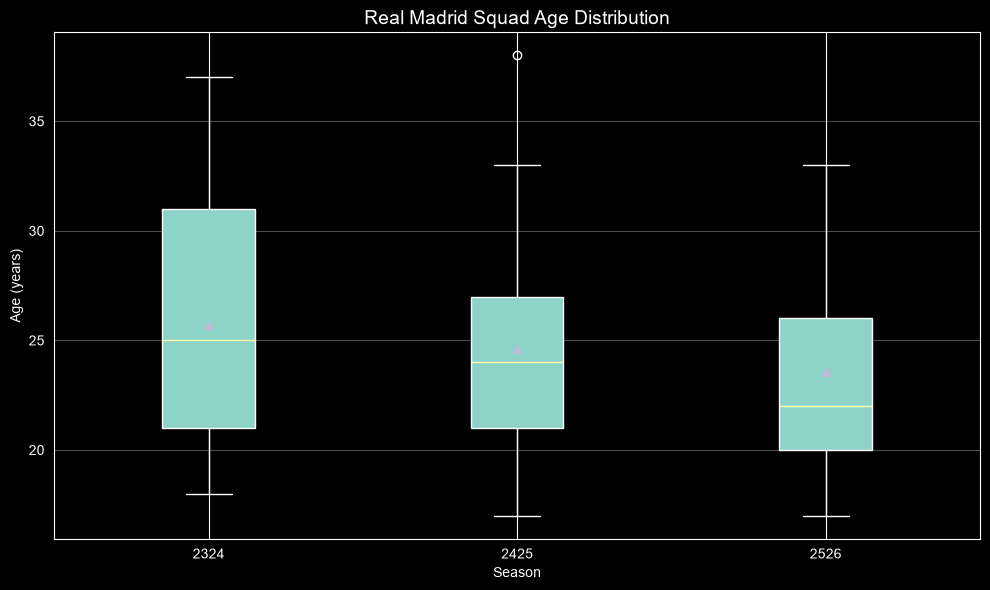

In [8]:
# Prepare age data
age_data = df[["season", "age"]].copy()

age_data["age"] = pd.to_numeric(
    age_data["age"], errors="coerce"
)

age_data = age_data.dropna(subset=["season", "age"])

# Sort seasons
seasons = sorted(age_data["season"].unique())

# Prepare groups
age_groups = [
    age_data.loc[
        age_data["season"] == season, "age"
    ].values
    for season in seasons
]

# Create plot
fig, ax = plt.subplots(figsize=(10, 6))

ax.boxplot(
    age_groups,
    tick_labels=seasons,
    patch_artist=True,
    showmeans=True
)

ax.set_title("Real Madrid Squad Age Distribution", fontsize=14)
ax.set_xlabel("Season")
ax.set_ylabel("Age (years)")

ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "eda_age_distribution.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

## 6. Attacking output

In [9]:
attacking_cols = [c for c in ["goals", "assists", "goal_contributions"] if c in df.columns]
if attacking_cols:
    season_attack = df.groupby("season")[attacking_cols].sum(min_count=1).reset_index()
    display(season_attack)

    if "goal_contributions" in df.columns:
        fig, ax = plt.subplots(figsize=(9, 5))
        ax.bar(season_attack["season"].astype(str), season_attack["goal_contributions"])
        ax.set_title("Player goal contributions recorded in the dataset")
        ax.set_xlabel("Season")
        ax.set_ylabel("Goals + assists")
        ax.grid(axis="y", alpha=0.25)
        plt.xticks(rotation=15)
        plt.tight_layout()
        plt.savefig(FIGURES_DIR / "eda_goal_contributions_by_season.png", dpi=160)
        plt.show()

    per90_cols = [c for c in ["goals_per_90", "assists_per_90", "goal_contributions_per_90"] if c in df.columns]
    if per90_cols:
        per90_summary = df.groupby("season")[per90_cols].median().round(3).reset_index()
        display(per90_summary)
else:
    print("Attacking metrics unavailable — skipping attacking analysis.")


,season,goals_per_90
0,2324,0.033
1,2425,0.000
2,2526,0.000


## 7. Position group coverage

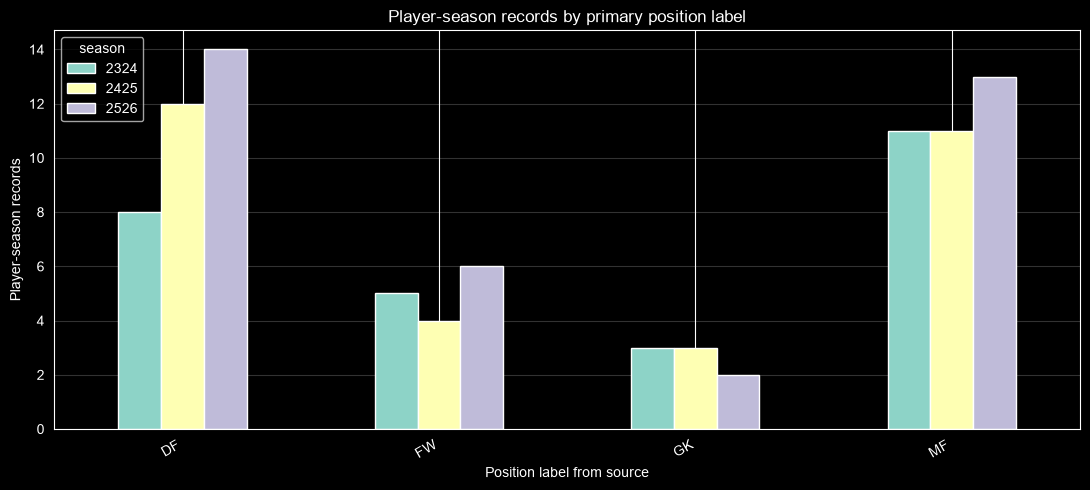

In [10]:
if "position" in df.columns:
    position_counts = (
        df.assign(position_group=df["position"].fillna("Unknown").astype(str).str.split(",").str[0].str.strip())
          .groupby(["season", "position_group"])
          .size()
          .rename("player_season_records")
          .reset_index()
    )
    display(position_counts.sort_values(["season", "player_season_records"], ascending=[True, False]))

    pivot = position_counts.pivot(index="position_group", columns="season", values="player_season_records").fillna(0)
    ax = pivot.plot(kind="bar", figsize=(11, 5))
    ax.set_title("Player-season records by primary position label")
    ax.set_xlabel("Position label from source")
    ax.set_ylabel("Player-season records")
    ax.grid(axis="y", alpha=0.2)
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "eda_position_coverage.png", dpi=160)
    plt.show()
else:
    print("Position column unavailable — skipping positional analysis.")


## 8. Identify potential transfer-needs signals

In [11]:
# This is a descriptive screening table, not a definitive squad-strength score.
# Low team coverage or low minutes can indicate limited usage, but can also reflect injuries,
# tactical choices, competition, age, or source coverage.
if "position" in df.columns and "minutes" in df.columns:
    df["position_group"] = df["position"].fillna("Unknown").astype(str).str.split(",").str[0].str.strip()
    position_usage = (
        df.groupby(["season", "position_group"])
          .agg(
              player_season_records=("player", "size"),
              total_minutes=("minutes", "sum"),
              median_minutes=("minutes", "median"),
              players=("player", "nunique")
          )
          .reset_index()
          .sort_values(["season", "total_minutes"], ascending=[True, False])
    )
    display(position_usage)
else:
    position_usage = pd.DataFrame()
    print("Position and/or minutes missing — cannot create position usage screening.")


,season,position_group,player_season_records,total_minutes,median_minutes,players
3,2324,MF,11,15396.0,1688.0,11
0,2324,DF,8,12813.0,1569.5,8
1,2324,FW,5,5951.0,1687.0,5
2,2324,GK,3,3420.0,1198.0,3
7,2425,MF,11,14277.0,1250.0,11
4,2425,DF,12,14226.0,971.5,12
5,2425,FW,4,5579.0,1308.0,4
6,2425,GK,3,3420.0,630.0,3
11,2526,MF,13,13854.0,684.0,13
8,2526,DF,14,12593.0,953.0,14


## 9. Export EDA tables

In [12]:
tables_to_export = {
    "eda_season_summary.csv": season_summary,
}
if "top_minutes" in globals():
    tables_to_export["eda_top_minutes_by_season.csv"] = top_minutes
if "age_summary" in globals():
    tables_to_export["eda_age_summary.csv"] = age_summary
if "season_attack" in globals():
    tables_to_export["eda_attacking_summary.csv"] = season_attack
if "position_counts" in globals():
    tables_to_export["eda_position_counts.csv"] = position_counts
if "position_usage" in globals() and not position_usage.empty:
    tables_to_export["eda_position_usage.csv"] = position_usage

for filename, table in tables_to_export.items():
    table.to_csv(REPORTS_DIR / filename, index=False)

print("Exported EDA tables:")
for filename in tables_to_export:
    print("-", REPORTS_DIR / filename)


Exported EDA tables:
- C:\Users\1alma\DataspellProjects\real-madrid-ai\reports\eda_season_summary.csv
- C:\Users\1alma\DataspellProjects\real-madrid-ai\reports\eda_top_minutes_by_season.csv
- C:\Users\1alma\DataspellProjects\real-madrid-ai\reports\eda_age_summary.csv
- C:\Users\1alma\DataspellProjects\real-madrid-ai\reports\eda_attacking_summary.csv
- C:\Users\1alma\DataspellProjects\real-madrid-ai\reports\eda_position_counts.csv
- C:\Users\1alma\DataspellProjects\real-madrid-ai\reports\eda_position_usage.csv
